In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import mpl_scatter_density
from matplotlib.colors import LinearSegmentedColormap

**Finding top peak signal for cycle 1 removed calls**

In [2]:
#load npz file
added_delta_all_cycles = []
removed_delta_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 11):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100unique_cycle'+str(i)+'_added_removed_CT20220302.npz'
    cycle_np_file = np.load(filename)
    added_delta_all_cycles.append(cycle_np_file['added_delta'])
    removed_delta_all_cycles.append(cycle_np_file['removed_delta'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [3]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [4]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/DHS_peak_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220215.npy'
DHS_peak_signal_array = np.load(file)

In [5]:
n_biosamples, n_DHSs = DHS_peak_signal_array.shape

In [6]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [7]:
#finding peak signal values of removed calls
removed_peak_signal_all_cycles = []
for i in range(10):
    print(i)
    removed_peak_signal_single_cycle = []
    for biosample, dhs in zip((removed_flat_inds_all_cycles[i] // n_DHSs), (removed_flat_inds_all_cycles[i] % n_DHSs)):
        removed_peak_signal_single_cycle.append(DHS_peak_signal_array[biosample, dhs])
    removed_peak_signal_single_cycle = np.array(removed_peak_signal_single_cycle)
    removed_peak_signal_all_cycles.append(removed_peak_signal_single_cycle)

0
1
2
3
4
5
6
7
8
9


In [51]:
#looking into the top peak signal -1 removed calls
top_100_peak_scores = np.flip(np.sort(removed_peak_signal_all_cycles[0])[-100:])

top_100_neg1_peak_signal_flat_inds = removed_flat_inds_all_cycles[0][np.argsort(-removed_peak_signal_all_cycles[0])[:100]]
top_100_neg1_peak_signal_DHS_inds = top_100_neg1_peak_signal_flat_inds % n_DHSs
top_100_neg1_peak_signal_biosample_inds = top_100_neg1_peak_signal_flat_inds // n_DHSs
top_100_neg1_peak_signal_biosamples = np.array(biosample_df.loc[top_100_neg1_peak_signal_biosample_inds]['Biosample name'])

top_100_neg1_peak_signal_chr = np.array(DHS_metadata.loc[top_100_neg1_peak_signal_DHS_inds]['seqname'])
top_100_neg1_peak_signal_start = np.array(DHS_metadata.loc[top_100_neg1_peak_signal_DHS_inds]['start'])
top_100_neg1_peak_signal_end = np.array(DHS_metadata.loc[top_100_neg1_peak_signal_DHS_inds]['end'])

In [16]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_delta_100unique_top_100_peak_signal_removed_calls_cycle1_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(str(top_100_neg1_peak_signal_chr[i]) + '\t' + str(top_100_neg1_peak_signal_start[i]) + '\t' + str(top_100_neg1_peak_signal_end[i]) + '\t' + str(top_100_peak_scores[i]) + ' ' + str(top_100_neg1_peak_signal_biosamples[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_delta_100unique_top_100_peak_signal_removed_calls_cycle1_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_delta_100unique_top_100_peak_signal_removed_calls_cycle1_CT20220304.bed


**Seeing if there are cases of a DHS being reassigned to a nearby DHS**

In [12]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100unique_cycle1_CT20220301.npz'
cycle_np_file = np.load(filename)
diff_flat = cycle_np_file['diff_flat_array']

In [32]:
right_neighbor_delta_all_cycles = []
left_neighbor_delta_all_cycles = []
for i in range(10):
    if i==0:
        cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')

        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_booldhsarr_basis_mixture_fillsize100unique_cycle1_CT20220301.npz'
        cycle_np_file = np.load(filename)
        cycle1_dhs_arr = cycle_np_file['new_dhs_array']
    else:
        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_booldhsarr_basis_mixture_fillsize100unique_cycle'+str(i)+'_CT20220301.npz'
        cycle_np_file = np.load(filename)
        cycle0_dhs_arr = cycle_np_file['new_dhs_array']

        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_booldhsarr_basis_mixture_fillsize100unique_cycle'+str(i+1)+'_CT20220301.npz'
        cycle_np_file = np.load(filename)
        cycle1_dhs_arr = cycle_np_file['new_dhs_array']
    
    #delta array
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100unique_cycle'+str(i+1)+'_CT20220301.npz'
    cycle_np_file = np.load(filename)
    diff_flat = cycle_np_file['diff_flat_array']
    
    #looking into the top peak signal -1 removed calls
#     top_peak_scores = np.flip(np.sort(removed_peak_signal_all_cycles[i]))

    top_neg1_peak_signal_flat_inds = removed_flat_inds_all_cycles[i][np.argsort(-removed_peak_signal_all_cycles[i])]
    top_neg1_peak_signal_DHS_inds = top_neg1_peak_signal_flat_inds % n_DHSs
    top_neg1_peak_signal_biosample_inds = top_neg1_peak_signal_flat_inds // n_DHSs
#     top_neg1_peak_signal_biosamples = np.array(biosample_df.loc[top_neg1_peak_signal_biosample_inds]['Biosample name'])

#     top_neg1_peak_signal_chr = np.array(DHS_metadata.loc[top_neg1_peak_signal_DHS_inds]['seqname'])
#     top_neg1_peak_signal_start = np.array(DHS_metadata.loc[top_neg1_peak_signal_DHS_inds]['start'])
#     top_neg1_peak_signal_end = np.array(DHS_metadata.loc[top_neg1_peak_signal_DHS_inds]['end'])
    
    right_neighbor_delta_all_cycles.append(diff_flat[top_neg1_peak_signal_flat_inds+1])
    left_neighbor_delta_all_cycles.append(diff_flat[top_neg1_peak_signal_flat_inds-1])
    
    cycle0_all_left_dhs = cycle0_dhs_arr[top_neg1_peak_signal_biosample_inds, top_neg1_peak_signal_DHS_inds-1].astype(int)
    cycle1_all_left_dhs = cycle1_dhs_arr[top_neg1_peak_signal_biosample_inds, top_neg1_peak_signal_DHS_inds-1].astype(int)

    cycle0_all_right_dhs = cycle0_dhs_arr[top_neg1_peak_signal_biosample_inds, top_neg1_peak_signal_DHS_inds+1].astype(int)
    cycle1_all_right_dhs = cycle1_dhs_arr[top_neg1_peak_signal_biosample_inds, top_neg1_peak_signal_DHS_inds+1].astype(int)
    
    print(i)
    print(len(np.where((cycle1_all_left_dhs - cycle0_all_left_dhs)==1)[0]))
    print(len(np.where((cycle1_all_right_dhs - cycle0_all_right_dhs)==1)[0]))
    print()

0
0
0

1
0
0

2
0
0

3
0
0

4
0
0

5
0
0

6
0
0

7
0
0

8
0
0

9
0
0



In [47]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_delta_vals_right_neighbor_to_removed_fillsize100unique_allcycles_CT20220307.pickle', 'wb')
pickle.dump(right_neighbor_delta_all_cycles, pickle_out)
pickle_out.close()
pickle_out = open('/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_delta_vals_left_neighbor_to_removed_fillsize100unique_allcycles_CT20220307.pickle', 'wb')
pickle.dump(left_neighbor_delta_all_cycles, pickle_out)
pickle_out.close()

In [85]:
total_neighbor_delta = []
for i in range(10):
    total_neighbor_delta.extend(right_neighbor_delta_all_cycles[i])
    total_neighbor_delta.extend(left_neighbor_delta_all_cycles[i])

In [96]:
max(total_neighbor_delta)

1.097913

Text(0.5, 1.0, 'Delta Values of Calls Neighboring Removed Calls for All Cycles\nDelta Flip, Flip Size=100 Unique Delta Values')

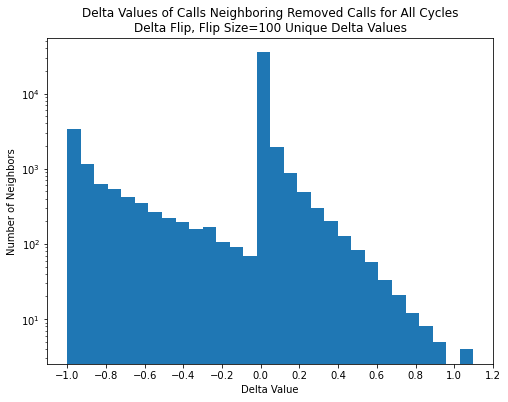

In [95]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

# for i in range(10):
#     plt.hist(right_neighbor_delta_all_cycles[i], bins=30)
# plt.hist(right_neighbor_delta_all_cycles[0], bins=20, histtype='step')

plt.hist(total_neighbor_delta, bins=30)

# plt.xlim([1.2, 2])
# plt.ylim([0.0004, 110])
plt.yscale('log')
# plt.legend(['Cycle 1', 'Cycle 2', 'Cycle 3', 'Cycle 4', 'Cycle 5', 'Cycle 6', 'Cycle 7', 'Cycle 8', 'Cycle 9', 'Cycle 10'], loc=(1.01, 0.53))
plt.xticks([-1, -0.8, -0.6, -0.4, -0.2, 0, 0.2, 0.4, 0.6, 0.8, 1, 1.2])
plt.xlabel('Delta Value')
plt.ylabel('Number of Neighbors')
plt.title('Delta Values of Calls Neighboring Removed Calls for All Cycles\nDelta Flip, Flip Size=100 Unique Delta Values')

In [17]:
cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')

filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_booldhsarr_basis_mixture_fillsize100unique_cycle1_CT20220301.npz'
cycle_np_file = np.load(filename)
cycle1_dhs_arr = cycle_np_file['new_dhs_array']

In [52]:
#looking into the top peak signal -1 removed calls
top_peak_scores = np.flip(np.sort(removed_peak_signal_all_cycles[0]))

top_neg1_peak_signal_flat_inds = removed_flat_inds_all_cycles[0][np.argsort(-removed_peak_signal_all_cycles[0])]
top_neg1_peak_signal_DHS_inds = top_neg1_peak_signal_flat_inds % n_DHSs
top_neg1_peak_signal_biosample_inds = top_neg1_peak_signal_flat_inds // n_DHSs
top_neg1_peak_signal_biosamples = np.array(biosample_df.loc[top_neg1_peak_signal_biosample_inds]['Biosample name'])

top_neg1_peak_signal_chr = np.array(DHS_metadata.loc[top_neg1_peak_signal_DHS_inds]['seqname'])
top_neg1_peak_signal_start = np.array(DHS_metadata.loc[top_neg1_peak_signal_DHS_inds]['start'])
top_neg1_peak_signal_end = np.array(DHS_metadata.loc[top_neg1_peak_signal_DHS_inds]['end'])

In [54]:
cycle0_all_left_dhs = cycle0_dhs_arr[top_neg1_peak_signal_biosample_inds, top_neg1_peak_signal_DHS_inds-1].astype(int)
cycle1_all_left_dhs = cycle1_dhs_arr[top_neg1_peak_signal_biosample_inds, top_neg1_peak_signal_DHS_inds-1].astype(int)

cycle0_all_right_dhs = cycle0_dhs_arr[top_neg1_peak_signal_biosample_inds, top_neg1_peak_signal_DHS_inds+1].astype(int)
cycle1_all_right_dhs = cycle1_dhs_arr[top_neg1_peak_signal_biosample_inds, top_neg1_peak_signal_DHS_inds+1].astype(int)

In [71]:
np.where((cycle1_all_left_dhs - cycle0_all_left_dhs)==1)[0]

array([], dtype=int64)

In [70]:
np.where((cycle1_all_right_dhs - cycle0_all_right_dhs)==1)[0]

array([], dtype=int64)

In [59]:
np.sum(cycle1_all_left_dhs - cycle0_all_left_dhs)

-93

In [60]:
np.sum(cycle1_all_right_dhs - cycle0_all_right_dhs)

-93

In [61]:
cycle1_all_left_dhs[16861]

0

In [62]:
cycle0_all_left_dhs[16861]

1

In [72]:
cycle0_dhs_arr[top_neg1_peak_signal_biosample_inds[16861], top_neg1_peak_signal_DHS_inds[16861]]

True

In [69]:
cycle1_dhs_arr[top_neg1_peak_signal_biosample_inds[16861], top_neg1_peak_signal_DHS_inds[16861]]

False